In [2]:
using Plots
using LinearAlgebra
using CUDA
using SparseArrays
using CUDA.CUSPARSE

Tomemos nuestra placa delgada metalica de L= 1m tal que su espesor sea despreciable. Con esto podemos tomar solo el cambio de la temperatura de manera espacial en x y su cambio en el tiempo.

Condiciones iniciales:

T(x,0) = 0

T(0,t) = 100

T(L,t) = 0

Constantes:

L =1

$\alpha$ = $1*10^-4 \frac{m^2}{s}$

Entonces ahora veamos la formulacion matematica, para este caso hare las derivadas hacia adelante con la siguiente formula:

$\frac{f(x+\delta x)-f(x)}{\delta x}$

Y para la segunda derivada:

$\frac{f(x+\delta x)-2f(x) + f(x-\delta x)}{(\delta x)^2}$

Aunque recordemos para el mallado se debe cumplir ciertas cosas para la convergencia, ya que en caso de tener un mallado muy fino este puede explotar.


Ahora apliquemos las formulas para nuestra ecuacion diferencial que tiene la siguiente forma:

$\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}$

De esta manera nos queda aplicando las formuals de antes:

$\frac{T^{i+1}_j-T^{i}_j}{\delta t} = \alpha \frac{T^i_{j+1}-2T^i_J+T^i_{j-1}}{(\delta x)^2}$

Al ser componentes vectoriales y como queremos la evolucion temporal depejamos a $T^{i+1}_j$

$T^{i+1}_j = \alpha \delta t \frac{T^i_{j+1}-2T^i_J+T^i_{j-1}}{(\delta x)^2} + T^{i}_j$

Pero recordemos que la derivada podemos representarla con una matriz 

$$T^{i+1}_j = \frac{\alpha \delta t}{(\delta x)^2}  \begin{bmatrix}
-2     &  1     &  0     &  0     & \dots  & 0 \\
 1     & -2     &  1     &  0     & \dots  & 0 \\
 0     &  1     & -2     &  1     & \dots  & 0 \\
 0     &  0     &  1     & -2     & \dots  & 0 \\
\vdots & \vdots & \vdots & \ddots & \ddots & \vdots \\
 0     &  0     &  0     & \dots  &  1     & -2
\end{bmatrix} T^{i}_j + T^{i}_j
$$

Aunque podemos optimizar aun este arreglo de manera nos quede lo siguiente:

$$T^{i+1}_j = [\frac{\alpha \delta t}{(\delta x)^2}  \begin{bmatrix}
-2     &  1     &  0     &  0     & \dots  & 0 \\
 1     & -2     &  1     &  0     & \dots  & 0 \\
 0     &  1     & -2     &  1     & \dots  & 0 \\
 0     &  0     &  1     & -2     & \dots  & 0 \\
\vdots & \vdots & \vdots & \ddots & \ddots & \vdots \\
 0     &  0     &  0     & \dots  &  1     & -2
\end{bmatrix} + I] T^{i}_j
$$

Donde I es la identidad, entonces podemos tomar esa suma de matriz de forma que para su avance temporal solo tenemos que multiplicarla, por recursividad, podemos ver como al final se veria algo asi:

$$T^{i}_j = (\frac{\alpha \delta t}{(\delta x)^2}  \begin{bmatrix}
-2     &  1     &  0     &  0     & \dots  & 0 \\
 1     & -2     &  1     &  0     & \dots  & 0 \\
 0     &  1     & -2     &  1     & \dots  & 0 \\
 0     &  0     &  1     & -2     & \dots  & 0 \\
\vdots & \vdots & \vdots & \ddots & \ddots & \vdots \\
 0     &  0     &  0     & \dots  &  1     & -2
\end{bmatrix} + I)^i T^{0}_j
$$

Donde ahora podemos obtener las i-iteraciones que queramos de manera mas sencilla y de manera lineal de acceder a ellas, vamos a programar esto ahora si

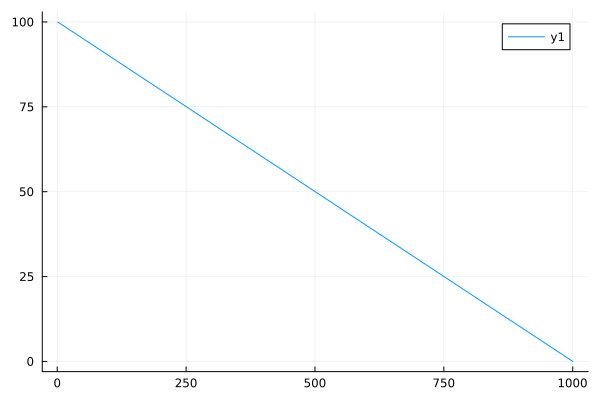

In [79]:
#Empezare a definir las variables de antes
L = 1
alpha = 1*10^-4
i = 1000 #este numero se cambia segun las iteraciones
h = L/(i-1)
k = h^2/(2*alpha) #se puede variar esto, pero me gustaria obtener el maximo ya que recordemos nuestro cambio en t debe ser menor o igual que el cuadrado de h entre 2 a alpha
T = zeros(i)
#condiciones iniciales:
T[1] =100
T[i] = 0
#Hagamos la matriz de antes
diag2 = fill(-2.0,i)
diag1 = fill(1.0, i-1) # como vemos se tiene que acabar en el ultimo
B = Tridiagonal(diag1,diag2,diag1) #aqui obtenemos nuestra matriz
B = alpha*k/((h)^2)*B + I
#pero como sabemos que hay una fuente de 0 C siempre en 0 y en 100 una fuente de 100 siempre debemos de modificar los extremos
B[1,1] = 1.0
B[1,2] = 0.0
B[i,i-1] = 0
B[i,i] = 1.0 
#lo voy a correr en grafica es mas rapido, sino quitamos algunos pasos de aqui:
B = CuSparseMatrixCSC(sparse(B))
T = CuArray(T)
tiempo = round(Int,10000/k) #aqui pongo el tiempo que quiera
for j in 1:tiempo
    global T = B*T
end
Tf = Array(T)
plot(Tf)

Codigo para alphas diferentes:



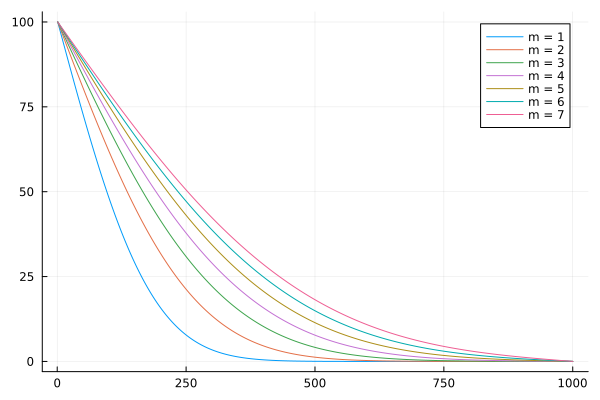

In [80]:
p= plot()
for m in 1:7
    L = 1
    alpha = 1e-4*m
    i = 1000 #este numero se cambia segun las iteraciones
    h = L/(i-1)
    k = h^2/(2*alpha) #se puede variar esto, pero me gustaria obtener el maximo ya que recordemos nuestro cambio en t debe ser menor o igual que el cuadrado de h entre 2 a alpha
    T = zeros(i)
    #condiciones iniciales:
    T[1] =100
    T[i] = 0
    #Hagamos la matriz de antes
    diag2 = fill(-2.0,i)
    diag1 = fill(1.0, i-1) # como vemos se tiene que acabar en el ultimo
    B = Tridiagonal(diag1,diag2,diag1) #aqui obtenemos nuestra matriz
    B = alpha*k/((h)^2)*B + I
    #pero como sabemos que hay una fuente de 0 C siempre en 0 y en 100 una fuente de 100 siempre debemos de modificar los extremos
    B[1,1] = 1.0
    B[1,2] = 0.0
    B[i,i-1] = 0
    B[i,i] = 1.0 
    #lo voy a correr en grafica es mas rapido, sino quitamos algunos pasos de aqui:
    B = CuSparseMatrixCSC(sparse(B))
    T = CuArray(T)
    tiempo = round(Int,100/k) #aqui pongo el tiempo que quiera
    for j in 1:tiempo
        T = B*T
    end
    Tf = Array(T)
    plot!(p,Tf,label ="m = $m")
end
display(p)

¿Qué representa la difusividad térmica en el comportamiento de tu simulación?

De aqui podemos ver como a medida crece alpha que es nuestra difusividad nos ayude a que el calor se propague de manera mas rapida en la barra, esto tomando como ejemplo la grafica 1 donde podemos ver que para un tiempo muy grande este tiende a ser una barra lineal, donde la temperatura llega a ese orden estacionario. Por lo que a mayores difusividad termica podemos decir que tendera a este estacionario con una rapidez mayor. A su vez es de interpretar que esta propiedad de los materiales es mas su facilidad de poder moverse, compartir esto con los de su alrededor.

Mapa de calor y gif evolucion temporal

[ Info: Saved animation to /home/artis/Documents/IFI 5 semestre/Mecanica estadistica/tarea difusion/Pruebafinalevtemp.gif


Plots.AnimatedGif("/home/artis/Documents/IFI 5 semestre/Mecanica estadistica/tarea difusion/Pruebafinalevtemp.gif")
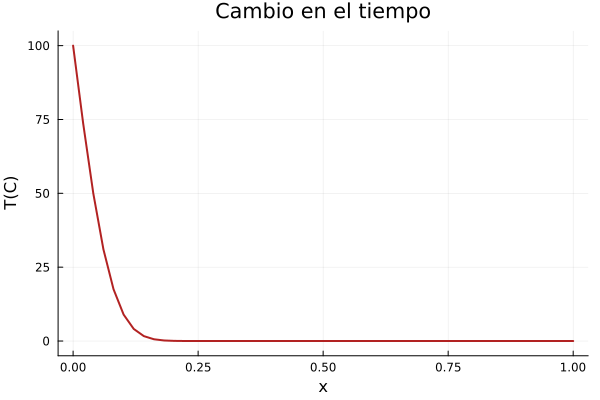

In [5]:
#Empezare a definir las variables de antes
L = 1
alpha = 1e-4
i = 100 #este numero se cambia segun las iteraciones
h = L/(i-1)
k = h^2/(2*alpha) #se puede variar esto, pero me gustaria obtener el maximo ya que recordemos nuestro cambio en t debe ser menor o igual que el cuadrado de h entre 2 a alpha
T = zeros(i)
#condiciones iniciales:
T[1] =100
T[i] = 0
#Hagamos la matriz de antes
diag2 = fill(-2.0,i)
diag1 = fill(1.0, i-1) # como vemos se tiene que acabar en el ultimo
B = Tridiagonal(diag1,diag2,diag1) #aqui obtenemos nuestra matriz
B = alpha*k/((h)^2)*B + I
#pero como sabemos que hay una fuente de 0 C siempre en 0 y en 100 una fuente de 100 siempre debemos de modificar los extremos
B[1,1] = 1.0
B[1,2] = 0.0
B[i,i-1] = 0
B[i,i] = 1.0 
#lo voy a correr en grafica es mas rapido, sino quitamos algunos pasos de aqui:
B = CuSparseMatrixCSC(sparse(B))
T = CuArray(T)
tiempo = round(Int,1800/k) #aqui pongo el tiempo que quiera
fpss = 100 #no voy a mentir, tuve que apoyarme con la IA para poder hacer este gif, quedo bonito
pasos_fpss = max(1,round(Int,tiempo / fpss))
anim = @animate for l in 1:fpss 
    global T
    for o in 1:pasos_fpss
        T = B*T
    end
    Tf = Array(T)
    tact = round(l * pasos_fpss * k, digits = 2)
    plot(range(0, L, length = i), Tf, title = "Cambio en el tiempo", xlabel = "x", ylabel = "T(C)", ylims = (-5, 105), legend = false, lw = 2, color = :firebrick)
end
gif(anim, "Pruebafinalevtemp.gif", fps = 20)

¿Qué observas en la forma en que se propaga el calor desde el borde izquierdo?

Se puede observar que en los bordes tanto izquiero como derecho permanece iguales al ser como "fuentes" ya que estas lo que hacen es mantenerse asi en todo el tiempo por como lo definimos antes, de esta manera podemos ver que en la evolucion temporal a medida pasa el tiempo este se empieza a ver como una linea recta

[ Info: Saved animation to /home/artis/Documents/IFI 5 semestre/Mecanica estadistica/tarea difusion/Pruebafinal.gif


Plots.AnimatedGif("/home/artis/Documents/IFI 5 semestre/Mecanica estadistica/tarea difusion/Pruebafinal.gif")
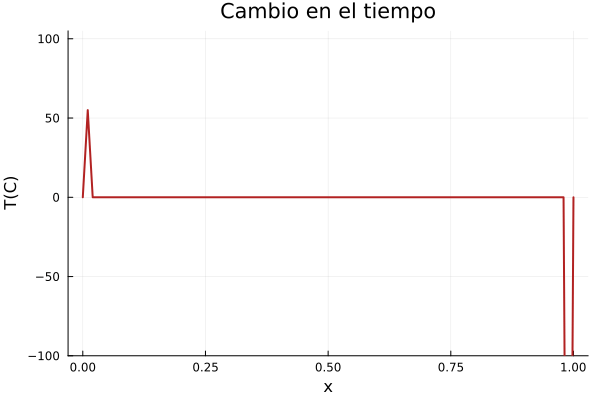

In [34]:
#Empezare a definir las variables de antes sin condiciones de frontera
L = 1
alpha = 1e-5
i = 100 #este numero se cambia segun las iteraciones
h = L/(i-1)
k = h^2/(2*alpha) #se puede variar esto, pero me gustaria obtener el maximo ya que recordemos nuestro cambio en t debe ser menor o igual que el cuadrado de h entre 2 a alpha
T = zeros(i)
#condiciones iniciales:
T[1] =110
T[i] = -1000
#Hagamos la matriz de antes
diag2 = fill(-2.0,i)
diag1 = fill(1.0, i-1) # como vemos se tiene que acabar en el ultimo
B = Tridiagonal(diag1,diag2,diag1) #aqui obtenemos nuestra matriz
B = alpha*k/((h)^2)*B + I
#lo voy a correr en grafica es mas rapido, sino quitamos algunos pasos de aqui:
B = CuSparseMatrixCSC(sparse(B))
T = CuArray(T)
tiempo = round(Int,100/k) #aqui pongo el tiempo que quiera
fpss = 100 #no voy a mentir, tuve que apoyarme con la IA para poder hacer este gif, quedo bonito
pasos_fpss = max(1,round(Int,tiempo / fpss))
anim = @animate for l in 1:fpss 
    global T
    for o in 1:pasos_fpss
        T = B*T
    end
    Tf = Array(T)
    tact = round(l * pasos_fpss * k, digits = 2)
    plot(range(0, L, length = i), Tf, title = "Cambio en el tiempo", xlabel = "x", ylabel = "T(C)", ylims = (-100, 105), legend = false, lw = 2, color = :firebrick)
end
gif(anim, "Pruebafinal.gif", fps = 20)

¿Qué pasa si modificas el valor de $\alpha$? ¿Y si cambias las condiciones de frontera?
Como ya vimos el pregunta 1 el ver como se va cambiando nuestra difusividad realintiza el proceso de equilibrio termico en donde llega a un estacionario que es que nuestra temperatura se vea como una linea perfecta, si cambiamos algunos valores como a que temperaturas esta inicialmente estan dichas fuentes podremos observar como la grafica va subiendo, la recta tiene un desplazamiento. Interesante es dejar la barra sin fuentes, que si pueda cambiar en el tiempo dependiendo de los puntos, lo que pude notar es que al ser solo unos pocos puntos y dependiendo del mallado pues el sistema tiende al equilibrio en 0 grados.

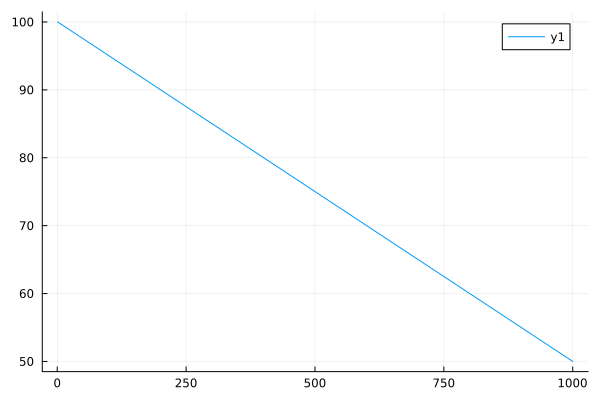

In [35]:
#Empezare a definir las variables de antes
L = 1
alpha = 1*10^-4
i = 1000 #este numero se cambia segun las iteraciones
h = L/(i-1)
k = h^2/(2*alpha) #se puede variar esto, pero me gustaria obtener el maximo ya que recordemos nuestro cambio en t debe ser menor o igual que el cuadrado de h entre 2 a alpha
T = zeros(i)
#condiciones iniciales:
T[1] =100
T[i] = 50
#Hagamos la matriz de antes
diag2 = fill(-2.0,i)
diag1 = fill(1.0, i-1) # como vemos se tiene que acabar en el ultimo
B = Tridiagonal(diag1,diag2,diag1) #aqui obtenemos nuestra matriz
B = alpha*k/((h)^2)*B + I
#pero como sabemos que hay una fuente de 0 C siempre en 0 y en 100 una fuente de 100 siempre debemos de modificar los extremos
B[1,1] = 1.0
B[1,2] = 0.0
B[i,i-1] = 0
B[i,i] = 1.0 
#lo voy a correr en grafica es mas rapido, sino quitamos algunos pasos de aqui:
B = CuSparseMatrixCSC(sparse(B))
T = CuArray(T)
tiempo = round(Int,10000/k) #aqui pongo el tiempo que quiera
for j in 1:tiempo
    global T = B*T
end
Tf = Array(T)
plot(Tf)

¿Qué aprendiste sobre la relación entre el modelo matemático y su implementación numérica?
Aprendi que hay que tener cuidado al momento de llevar alguna relacion matematica a su implementacion numerica, ya que en el camino pueden haber divergencias en los mallados o que no sea el mejor acomodo. Tambien aprendi que mi compu puede explotar y que debo poner adecuadamente los limites para que este no se rompa, ya que es importante conocer el limite y comparar con lo que obtenemos de datos.
Por ultimo el que al final de cuentas debemos de explorar siempre lo que nos de la simulacion y dudar si es un comportamiento que esperariamos de las matematicas no usarlo como caja oscura.